### Ансамбли и важность признаков. Random Forest, Gradient Boosting и Voting

In [1]:
import sys
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

sys.path.insert(0, str(Path("..").resolve()))
import matplotlib.pyplot as plt
import pandas as pd
import shap
from sklearn.metrics import classification_report, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_sample_weight
from src.common import load_dataset, split_data, get_feature_names, evaluate, plot_confusion
from src.models import build_decision_tree, build_random_forest, build_gradient_boosting, build_voting_ensemble
from src.metrics import compute_oob_roc_auc, compute_mdi_importance, compute_perm_importance, cross_validate_model

df = load_dataset()
X_train, X_test, y_train, y_test = split_data(df, test_size=0.2, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

rf_val = []
for n_est in [50, 100, 150, 200]:
    p = build_random_forest(n_estimators=n_est)
    p.fit(X_tr, y_tr)
    rf_val.append({
        "Число деревьев": n_est,
        "OOB ROC-AUC": round(compute_oob_roc_auc(p.named_steps["clf"], y_tr), 4),
        "Валидация ROC-AUC": round(roc_auc_score(y_val, p.predict_proba(X_val)[:, 1]), 4),
    })
print("Random Forest на валидации:")
display(pd.DataFrame(rf_val))

sw_tr = compute_sample_weight("balanced", y_tr)
gb_val = []
for lr in [0.05, 0.1]:
    for n_est in [80, 120, 150]:
        p = build_gradient_boosting(n_estimators=n_est, learning_rate=lr)
        p.fit(X_tr, y_tr, clf__sample_weight=sw_tr)
        gb_val.append({
            "Шаг обучения": lr,
            "Число этапов": n_est,
            "Валидация ROC-AUC": round(roc_auc_score(y_val, p.predict_proba(X_val)[:, 1]), 4),
        })
print("Gradient Boosting на валидации:")
display(pd.DataFrame(gb_val))

Random Forest на валидации:


,Число деревьев,OOB ROC-AUC,Валидация ROC-AUC
0,50,0.9189,0.9324
1,100,0.9233,0.9338
2,150,0.9247,0.9336
3,200,0.9252,0.9338


Gradient Boosting на валидации:


,Шаг обучения,Число этапов,Валидация ROC-AUC
0,0.05,80,0.9226
1,0.05,120,0.9289
2,0.05,150,0.9318
3,0.10,80,0.9350
4,0.10,120,0.9389
5,0.10,150,0.9397


,Модель,OOB ROC-AUC,CV ROC-AUC,Тест ROC-AUC,Тест F1,Полнота,G-среднее
0,Дерево гл. 3,-,0.8317,0.8335,0.4440,0.7854,0.7766
1,Random Forest,0.9288,0.9280,0.9280,0.6005,0.8176,0.8482
2,Gradient Boosting,-,0.9335,0.9295,0.5830,0.8715,0.8616
3,Voting,-,0.9331,0.9313,0.5795,0.8696,0.8598



Отчет по Voting:
              precision    recall  f1-score   support

       Отказ       0.98      0.85      0.91      7985
     Депозит       0.43      0.87      0.58      1058

    accuracy                           0.85      9043
   macro avg       0.71      0.86      0.74      9043
weighted avg       0.92      0.85      0.87      9043



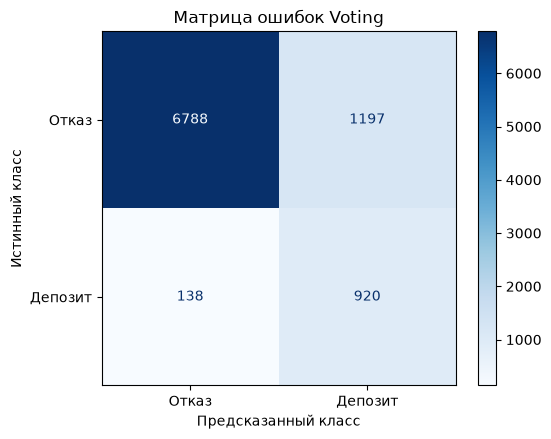

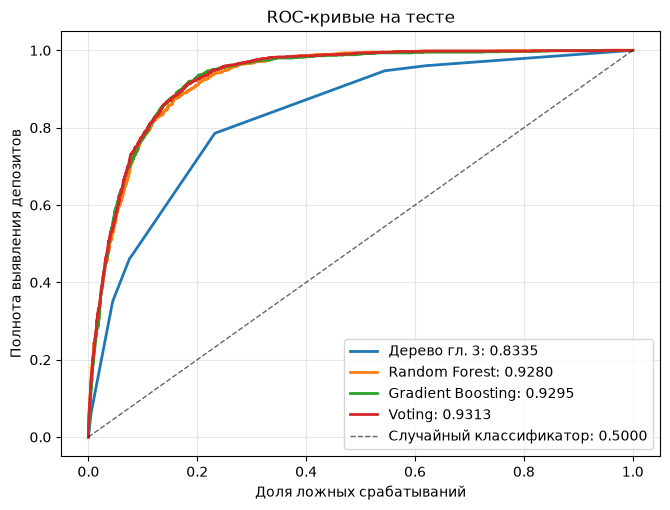

In [3]:
sw_train = compute_sample_weight("balanced", y_train)
models = [
    ("Дерево гл. 3", build_decision_tree(max_depth=3), False),
    ("Random Forest", build_random_forest(n_estimators=200, n_jobs=1), False),
    ("Gradient Boosting", build_gradient_boosting(n_estimators=150, learning_rate=0.1), True),
    ("Voting", build_voting_ensemble(), True),
]

summary = []
fitted = {}
for name, pipe, use_sw in models:
    cv_m = cross_validate_model(pipe, X_train, y_train, cv_splits=5, sample_weight=sw_train if use_sw else None)
    if use_sw:
        pipe.fit(X_train, y_train, clf__sample_weight=sw_train)
    else:
        pipe.fit(X_train, y_train)
    oob = compute_oob_roc_auc(pipe.named_steps["clf"], y_train) if name == "Random Forest" else None
    te_m = evaluate(pipe, X_test, y_test)
    summary.append({
        "Модель": name,
        "OOB ROC-AUC": round(oob, 4) if oob is not None else "-",
        "CV ROC-AUC": round(cv_m["cv_roc_auc"], 4),
        "Тест ROC-AUC": round(te_m["roc_auc"], 4),
        "Тест F1": round(te_m["f1"], 4),
        "Полнота": round(te_m["recall"], 4),
        "G-среднее": round(te_m["gmean"], 4),
    })
    fitted[name] = pipe

display(pd.DataFrame(summary))
print("\nОтчет по Voting:")
print(classification_report(y_test, fitted["Voting"].predict(X_test), target_names=["Отказ", "Депозит"]))

fig = plot_confusion(fitted["Voting"], X_test, y_test)
plt.title("Матрица ошибок Voting")
plt.show()

plt.figure(figsize=(6.8, 5.2))
for name, pipe, _ in models:
    prob = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc_val = next(r["Тест ROC-AUC"] for r in summary if r["Модель"] == name)
    plt.plot(fpr, tpr, lw=2, label=f"{name}: {auc_val:.4f}")
plt.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.6, label="Случайный классификатор: 0.5000")
plt.xlabel("Доля ложных срабатываний")
plt.ylabel("Полнота выявления депозитов")
plt.title("ROC-кривые на тесте")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Топ-15 признаков по важности:


,feature,importance
0,duration,0.466114
1,poutcome_success,0.107100
2,contact_unknown,0.082342
3,housing_yes,0.034368
4,pdays,0.033209
5,day_of_week,0.031588
6,age,0.028849
7,month_mar,0.027130
8,month_oct,0.025921
9,balance,0.017523


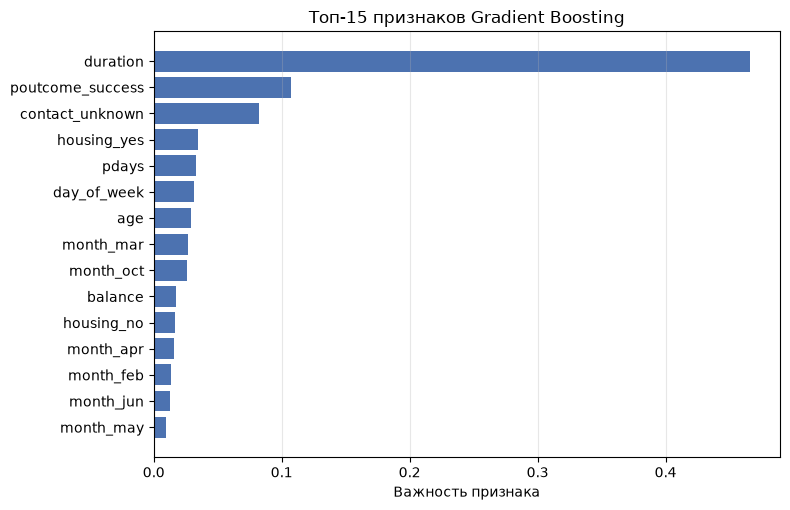

Топ-10 признаков по перестановке:


,feature,perm_importance
0,duration,0.229563
1,contact_unknown,0.023837
2,day_of_week,0.019416
3,pdays,0.008475
4,month_feb,0.007614
5,month_jun,0.006531
6,poutcome_success,0.006531
7,age,0.005898
8,month_apr,0.005856
9,month_oct,0.005723


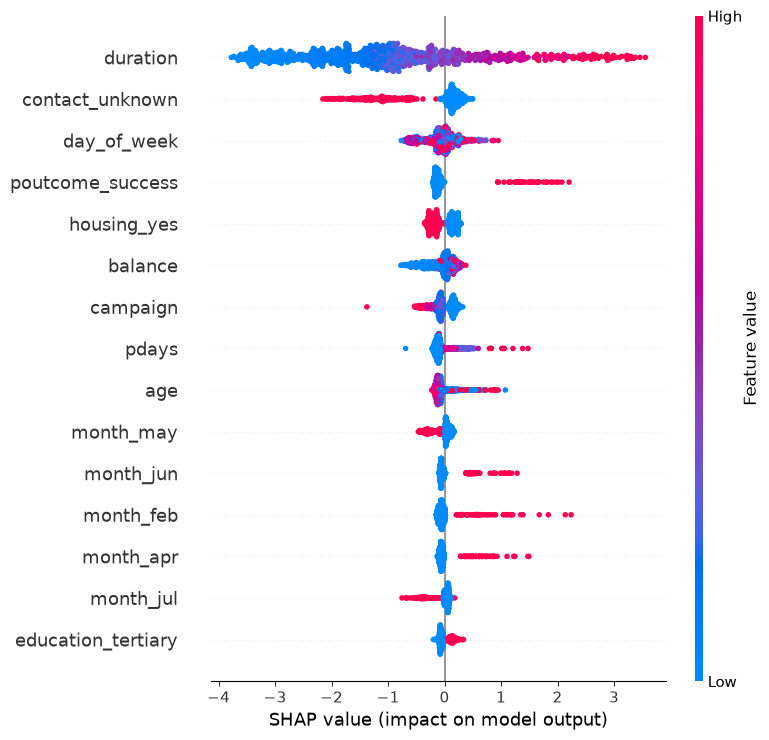

In [5]:
gb_pipe = fitted["Gradient Boosting"]
feat_names = get_feature_names(gb_pipe.named_steps["pre"])
mdi_df = compute_mdi_importance(gb_pipe.named_steps["clf"], feat_names)
print("Топ-15 признаков по важности:")
display(mdi_df.head(15))

top15 = mdi_df.head(15).iloc[::-1]
plt.figure(figsize=(8, 5.2))
plt.barh(top15["feature"], top15["importance"], color="#4C72B0")
plt.xlabel("Важность признака")
plt.title("Топ-15 признаков Gradient Boosting")
plt.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

X_test_proc = gb_pipe.named_steps["pre"].transform(X_test)
X_val_proc = gb_pipe.named_steps["pre"].transform(X_val)
perm_df = compute_perm_importance(gb_pipe.named_steps["clf"], X_val_proc, y_val, feat_names)
print("Топ-10 признаков по перестановке:")
display(perm_df.head(10))

X_shap = pd.DataFrame(X_test_proc[:1000], columns=feat_names)
explainer = shap.TreeExplainer(gb_pipe.named_steps["clf"])
shap_vals = explainer.shap_values(X_shap)
shap.summary_plot(shap_vals, X_shap, max_display=15, show=False)
plt.tight_layout()
plt.show()

## Вывод: 
#### На прогноз сильно влияют длительность разговора и то, открывал ли клиент депозит раньше: оба фактора сильно повышают вероятность согласия. И наоборот – отсутствие указанного телефона, ипотека и звонки в мае или июле чаще ведут к отказу.